## Intro to Data Science and Visualization - 2025/26

This notebook analyzes the SUPPORT2 dataset which contains data from seriously ill hospital patients. 

The goal is to predict whether a patient will die within 180 days of enrollment using measurements taken at day 3 of their hospital stay.

## 1 - Data Cleaning and Tidying


### Loading the data and take a look


We have columns that contains categorical(ex. sex, race etc.) and numerical (ex. age, hrt etc.)values 

In [42]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/dataset.csv')
df_default = df.copy()
print(df.info()) 


<class 'pandas.DataFrame'>
RangeIndex: 9355 entries, 0 to 9354
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 9355 non-null   float64
 1   sex                 9355 non-null   str    
 2   num.co              9355 non-null   int64  
 3   diabetes            9355 non-null   int64  
 4   dementia            9355 non-null   int64  
 5   meanbp              9354 non-null   float64
 6   hrt                 9354 non-null   float64
 7   resp                9354 non-null   float64
 8   temp                9354 non-null   float64
 9   crea                9287 non-null   float64
 10  sod                 9354 non-null   float64
 11  adlsc               9355 non-null   float64
 12  hday                9355 non-null   int64  
 13  ca                  9355 non-null   str    
 14  scoma               9354 non-null   float64
 15  dzclass             9355 non-null   str    
 16  sps              

We have 26 columns, 9355 rows in this dataset
First and last 5 rows for take a look and understand the dataset

In [43]:
print(df.shape) 
print(df.head(5)) 
print(df.tail(5)) 

(9355, 26)
        age     sex  num.co  diabetes  dementia  meanbp    hrt  resp  \
0  62.84998    male       0         0         0    97.0   69.0  22.0   
1  60.33899  female       2         0         0    43.0  112.0  34.0   
2  52.74698  female       2         0         0    70.0   88.0  28.0   
3  42.38498  female       2         0         0    75.0   88.0  32.0   
4  79.88495  female       1         0         0    59.0  112.0  20.0   

       temp      crea  ...        sps  urine        ph   race   edu adls  \
0  36.00000  1.199951  ...  33.898438    NaN  7.459961  other  11.0  7.0   
1  34.59375  5.500000  ...  52.695312    NaN  7.250000  white  12.0  1.0   
2  37.39844  2.000000  ...  20.500000    NaN  7.459961  white  12.0  0.0   
3  35.00000  0.799927  ...  20.097656    NaN       NaN  white  11.0  0.0   
4  37.89844  0.799927  ...  23.500000    NaN  7.509766    NaN   NaN  2.0   

   death  totcst  totmcst dzclass_death_rate  
0      0     NaN      NaN           0.887324  
1    

We have missing values in the dataset
Statistical summary of columns

In [44]:
print(df.isna().sum()) 
print(df.describe(include='all'))

age                      0
sex                      0
num.co                   0
diabetes                 0
dementia                 0
meanbp                   1
hrt                      1
resp                     1
temp                     1
crea                    68
sod                      1
adlsc                    0
hday                     0
ca                       0
scoma                    1
dzclass                  0
sps                      1
urine                 4999
ph                    3746
race                  3733
edu                   1679
adls                  2949
death                    0
totcst                 912
totmcst               3575
dzclass_death_rate       0
dtype: int64
                age   sex       num.co     diabetes     dementia       meanbp  \
count   9355.000000  9355  9355.000000  9355.000000  9355.000000  9354.000000   
unique          NaN     2          NaN          NaN          NaN          NaN   
top             NaN  male          NaN    

Correlations between numerical columns

In [45]:
print(df_default.corr(numeric_only=True)) 

                         age    num.co  diabetes  dementia    meanbp  \
age                 1.000000  0.130643  0.097527  0.197171 -0.038686   
num.co              0.130643  1.000000  0.385212  0.140103 -0.014061   
diabetes            0.097527  0.385212  1.000000  0.030513 -0.004647   
dementia            0.197171  0.140103  0.030513  1.000000 -0.001555   
meanbp             -0.038686 -0.014061 -0.004647 -0.001555  1.000000   
hrt                -0.126554 -0.068085 -0.061103 -0.027131  0.067232   
resp               -0.019657  0.010343 -0.034634  0.008940  0.068374   
temp               -0.090812 -0.117182 -0.010868 -0.005367 -0.001506   
crea                0.002525  0.031006  0.060587 -0.004108 -0.084881   
sod                 0.013980 -0.030584  0.012240  0.029738  0.059784   
adlsc               0.116782  0.143926  0.067387  0.252090 -0.017191   
hday               -0.072281 -0.082369 -0.009588 -0.029131 -0.002992   
scoma               0.010726 -0.021617 -0.013063  0.022367 -0.00

### Fixing the dataset

Look to total duplicated rows 
Dropping these duplicated rows for better and cleaner data
for confirm, is these duplicated rows are dropped in first we have 9355 rows

In [46]:
print(len(df))
print(df.duplicated().sum()) 
df.drop_duplicates(inplace= True)
df.dropna(how='all', inplace=True) 
print(len(df)) 

9355
250
9105


These columns contain text categories so we convert them from string to pandas category type. This tells pandas they are categorical values,
not free text and confirm.

In [47]:
categorical_columns = ['sex', 'race', 'dzclass', 'ca'] 
for c in categorical_columns:
    df[c] = df[c].astype('category')
print(df.info()) 

<class 'pandas.DataFrame'>
RangeIndex: 9105 entries, 0 to 9104
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   age                 9105 non-null   float64 
 1   sex                 9105 non-null   category
 2   num.co              9105 non-null   int64   
 3   diabetes            9105 non-null   int64   
 4   dementia            9105 non-null   int64   
 5   meanbp              9104 non-null   float64 
 6   hrt                 9104 non-null   float64 
 7   resp                9104 non-null   float64 
 8   temp                9104 non-null   float64 
 9   crea                9038 non-null   float64 
 10  sod                 9104 non-null   float64 
 11  adlsc               9105 non-null   float64 
 12  hday                9105 non-null   int64   
 13  ca                  9105 non-null   category
 14  scoma               9104 non-null   float64 
 15  dzclass             9105 non-null   category
 16 

finding the outlier values and replacing outlier values with nan because after we can fill with suitable value.

In [48]:
print(sorted(df['scoma'].unique())) 
print('sum of outlier values: ',(df['scoma'] == -999).sum())
df['scoma'] = df['scoma'].replace(-999, np.nan)

[np.float64(-999.0), np.float64(0.0), np.float64(9.0), np.float64(26.0), np.float64(37.0), np.float64(41.0), np.float64(44.0), np.float64(55.0), np.float64(61.0), np.float64(89.0), np.float64(94.0), np.float64(100.0), np.float64(nan)]
sum of outlier values:  455


For 'hday' not useful info for project in readme file it says the tests did in day 3 ----
For 'adls' adls and adlsc very similar/highly correlated and adls has too much missing value

In [49]:
print('missing value of adls',df['adls'].isna().sum())
print('missing value of adlsc',df['adlsc'].isna().sum())

df = df.drop(columns=['hday', 'adls'])

missing value of adls 2867
missing value of adlsc 0


We cant guess someone's race, so instead of deleting 3642 rows of the data we just label the missing values as unknown.

*Fixed after the course:* the first version converted to text before filling, so missing values became the string `'nan'` instead of `'unknown'`. Now we fill first, then convert.

In [50]:
print(df['race'].isna().sum())

# race is already a category column, so: back to plain text -> fill missing -> category again
df['race'] = df['race'].astype('object').fillna('unknown').astype('category')

print(df['race'].isna().sum())
print(df['race'].value_counts())

3642
0
race
white       4347
unknown     3642
black        827
hispanic     172
other         72
asian         45
Name: count, dtype: int64


The cost columns (totcst, totmcst) are finalizing end of the patient's hospital stay
so they would not be available at day 3 when a real prediction needs to be made. using
them like cheating for model / way better results than actual results

In [51]:
df = df.drop(['totcst','totmcst','dzclass_death_rate'], axis=1)

We bin them into groups because years of education is harder to visualize

In [52]:
bins = [0,8,12,16,100]
labels = ['primary','secondary','college','graduate']
df['edu_group'] = pd.cut(df['edu'], bins=bins, labels=labels, right=False) 
print(df['edu_group'].value_counts())

edu_group
college      3689
secondary    2047
graduate     1099
primary       636
Name: count, dtype: int64


In [53]:
print(df.shape) 
print(df.columns)
#final shape and columns 

(9105, 22)
Index(['age', 'sex', 'num.co', 'diabetes', 'dementia', 'meanbp', 'hrt', 'resp',
       'temp', 'crea', 'sod', 'adlsc', 'ca', 'scoma', 'dzclass', 'sps',
       'urine', 'ph', 'race', 'edu', 'death', 'edu_group'],
      dtype='str')


### Dataset distribution plots

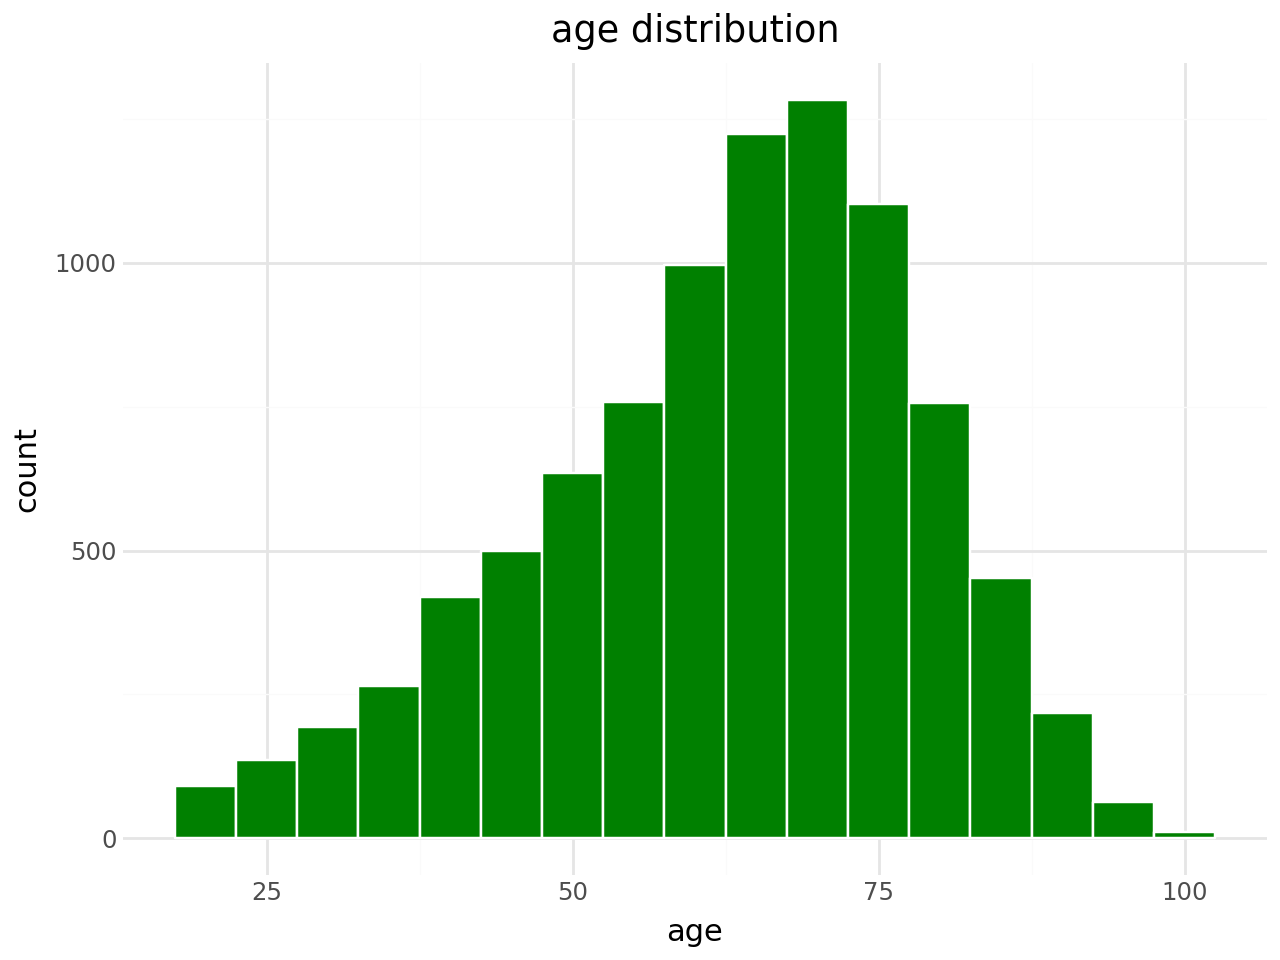

In [54]:
from plotnine import *

(ggplot(df, aes(x='age'))
 +geom_histogram(binwidth = 5, fill = 'green', color = 'white')
 + xlab('age') + ylab('count')
 +ggtitle('age distribution')
 + theme_minimal())

Most patients are between 40 and 80 years old. The distribution is slightly left skewed meaning younger patients are less common in this dataset, that makes sense as seriously ill patients tend to be older.

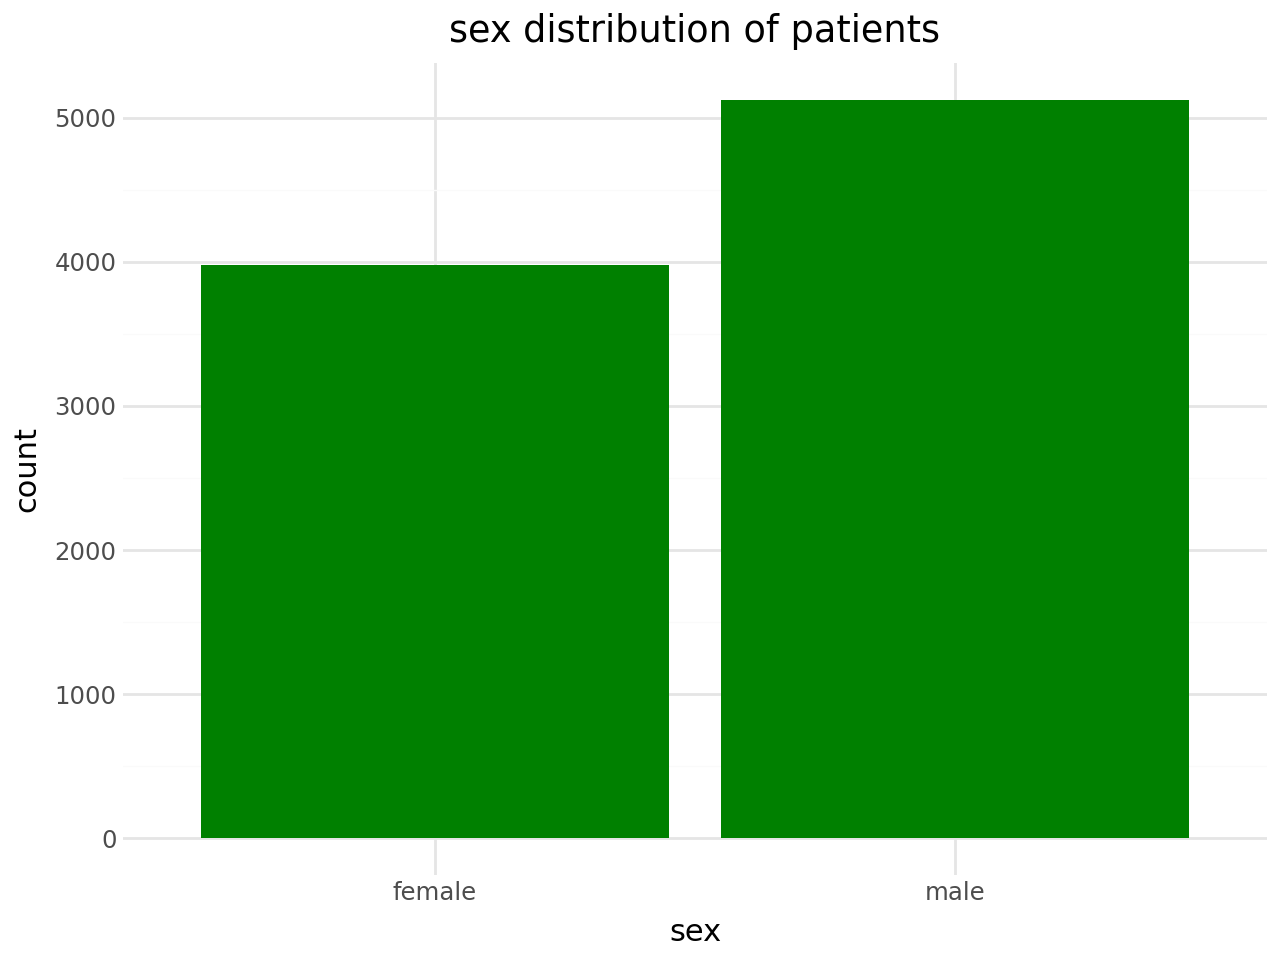

In [55]:
(ggplot(df, aes(x='sex'))
 +geom_bar(fill ='green')
 +xlab('sex')+ylab('count')
 +theme_minimal()
 +ggtitle('sex distribution of patients'))

The dataset has more male patients than female patients, but the difference is not extreme so both groups are well represented.

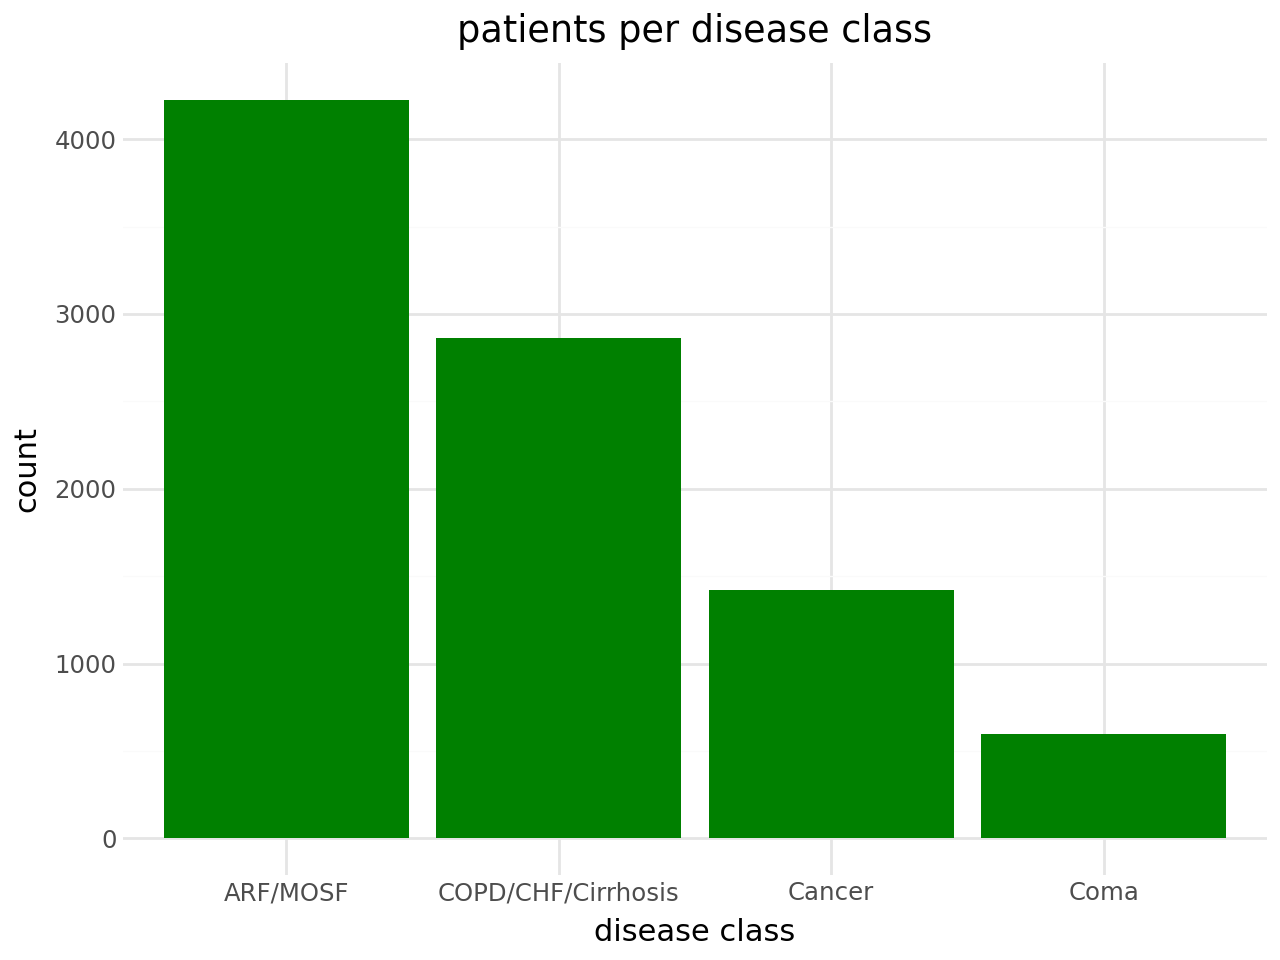

In [56]:
(ggplot(df,aes(x='dzclass'))
 +geom_bar(fill ='green')
 +xlab('disease class')+ylab('count')
 +theme_minimal()
 + ggtitle('patients per disease class'))

COPD/CHF/Cirrhosis and ARF/MOSF are the most common disease classes. Coma and Cancer have fewer patients. This means the dataset is not perfectly balanced across disease classes.

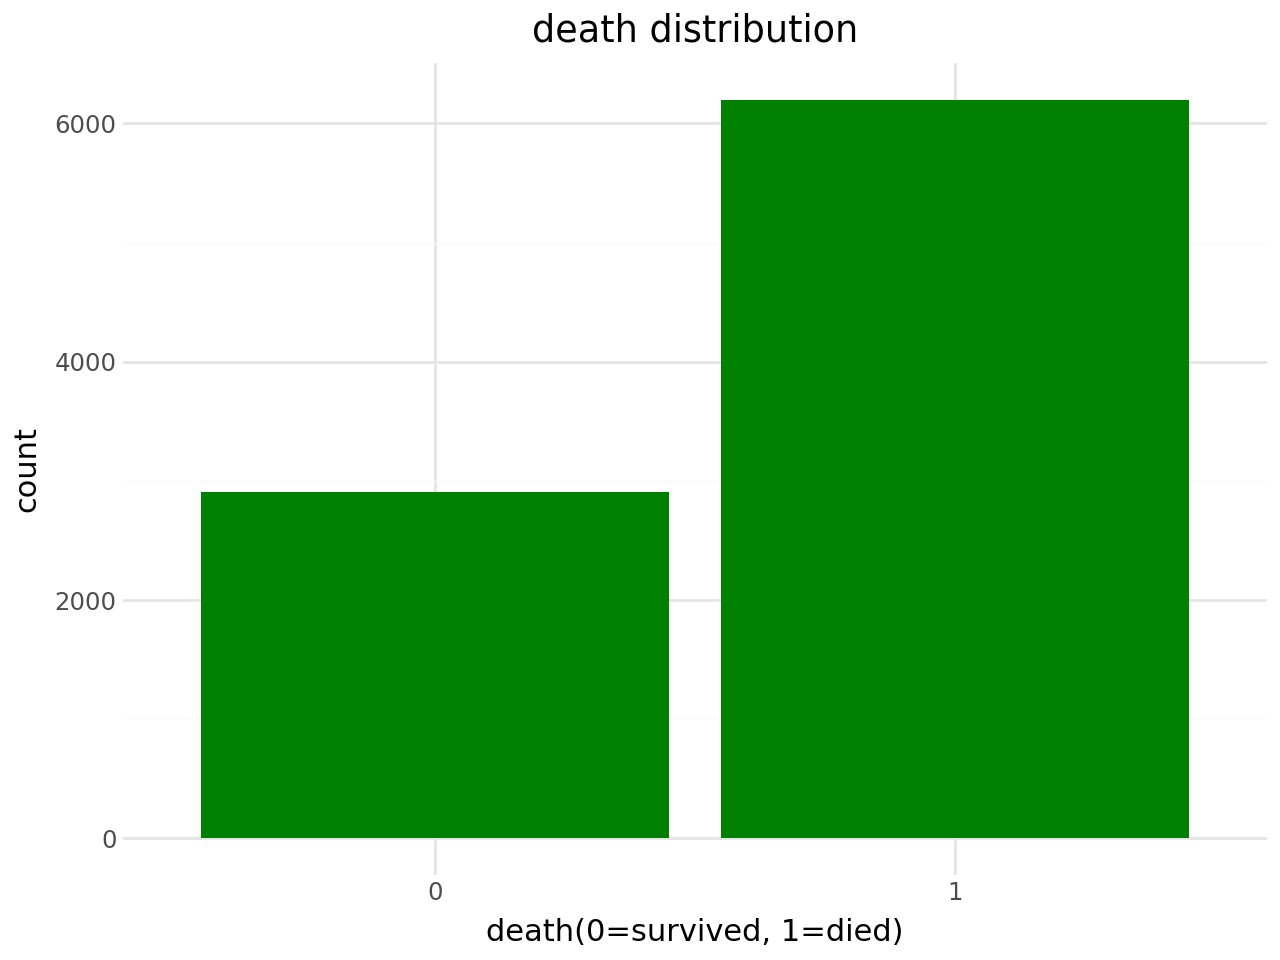

In [57]:
(ggplot(df, aes(x= 'death.astype(str)'))
 +geom_bar(fill='green')
 +xlab('death(0=survived, 1=died)')+ ylab('count')
 +ggtitle('death distribution')
 +theme_minimal())

About 68% of patients died within 180 days. This means the dataset is imbalanced the died class is the majority. A model that always predicts "died" would already get 68% accuracy, so we need to look beyond accuracy when evaluating the classifier.

## 2 - Data Quality Assessment

Percent of missing values in columns 

In [58]:
missing_values = df.isna().sum()
missing_percent = ((missing_values/len(df)) * 100).round(1)
missing_df = pd.DataFrame({'column': missing_percent.index, 'missing_pct':  missing_percent.values})
missing_df = missing_df[missing_df['missing_pct'] > 0]
print(missing_df) 

       column  missing_pct
9        crea          0.7
13      scoma          5.0
16      urine         53.4
17         ph         40.0
19        edu         17.9
21  edu_group         17.9


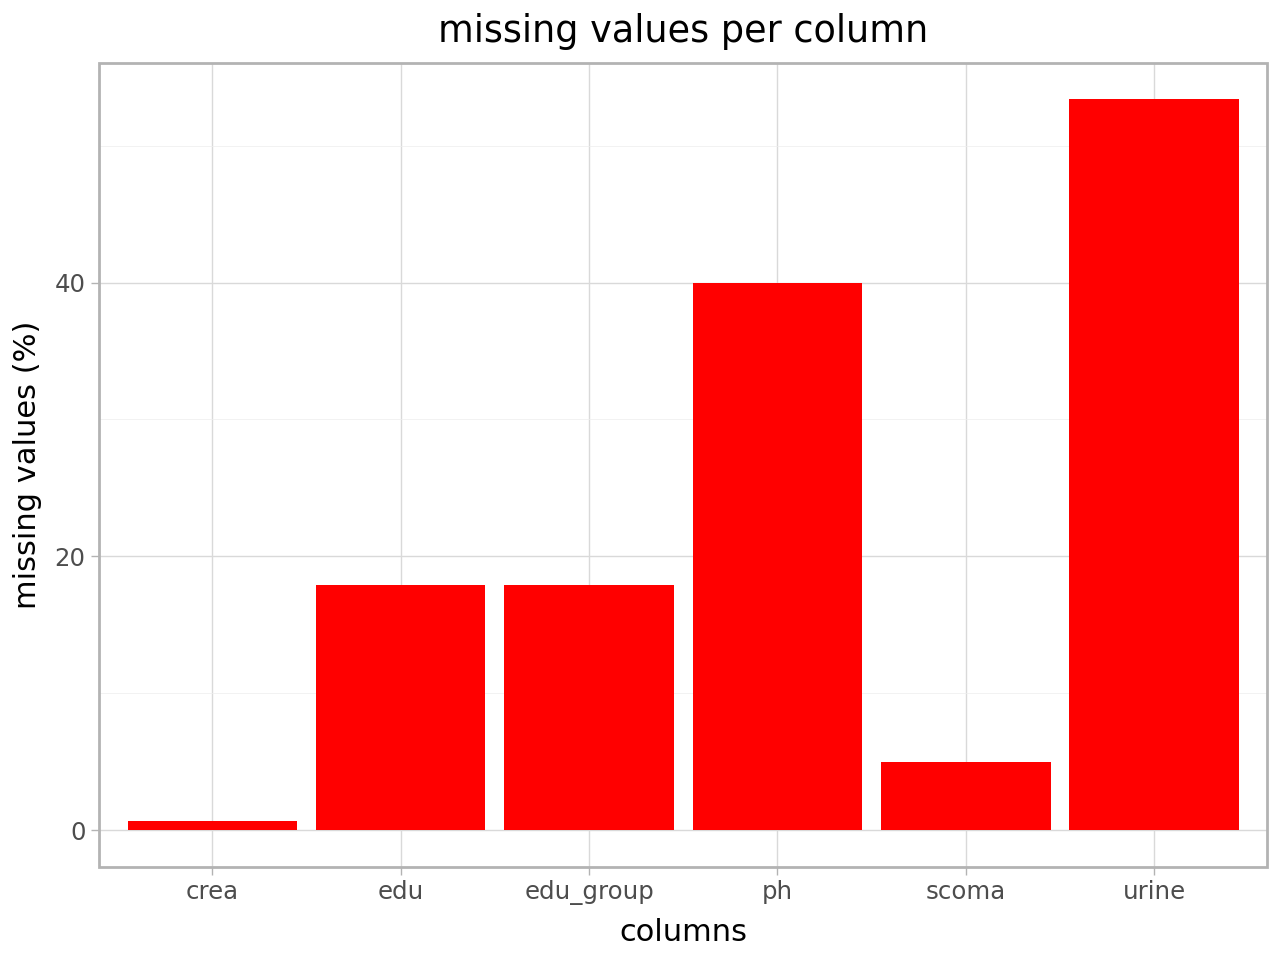

In [59]:
(ggplot(missing_df, aes(x='column', y='missing_pct'))
 +geom_col(fill = 'red')
 +xlab('columns') + ylab('missing values (%)')
 +ggtitle('missing values per column')
 +theme_light()) 

imputation strategy:

column = urine ----- missing = 53% ----- strategy = median ----- why: based on expert guidance provided in hints.md and median is safer than mean

column = ph ----- missing = 40% -----strategy = mean ----- why: distribution is near-normal

column = edu ----- missing = 18% -----strategy = median ----- why: right skewed distribution

column = crea,others ----- missing = 1% -----  strategy = median ----- why: median is safer than mean

The imputation is applied in section 4, fit only on training data not the whole dataset. This avoids leaking test statistics into training

## 3 - Data Visualizations


In [60]:
df_default = df_default.drop_duplicates().reset_index(drop=True)

sps_by_class = df_default.groupby('dzclass')['sps'].median().reset_index()
sps_by_class.columns = ['dzclass', 'median_sps']
print(sps_by_class)

              dzclass  median_sps
0            ARF/MOSF   28.097656
1  COPD/CHF/Cirrhosis   21.000000
2              Cancer   17.398438
3                Coma   23.548828


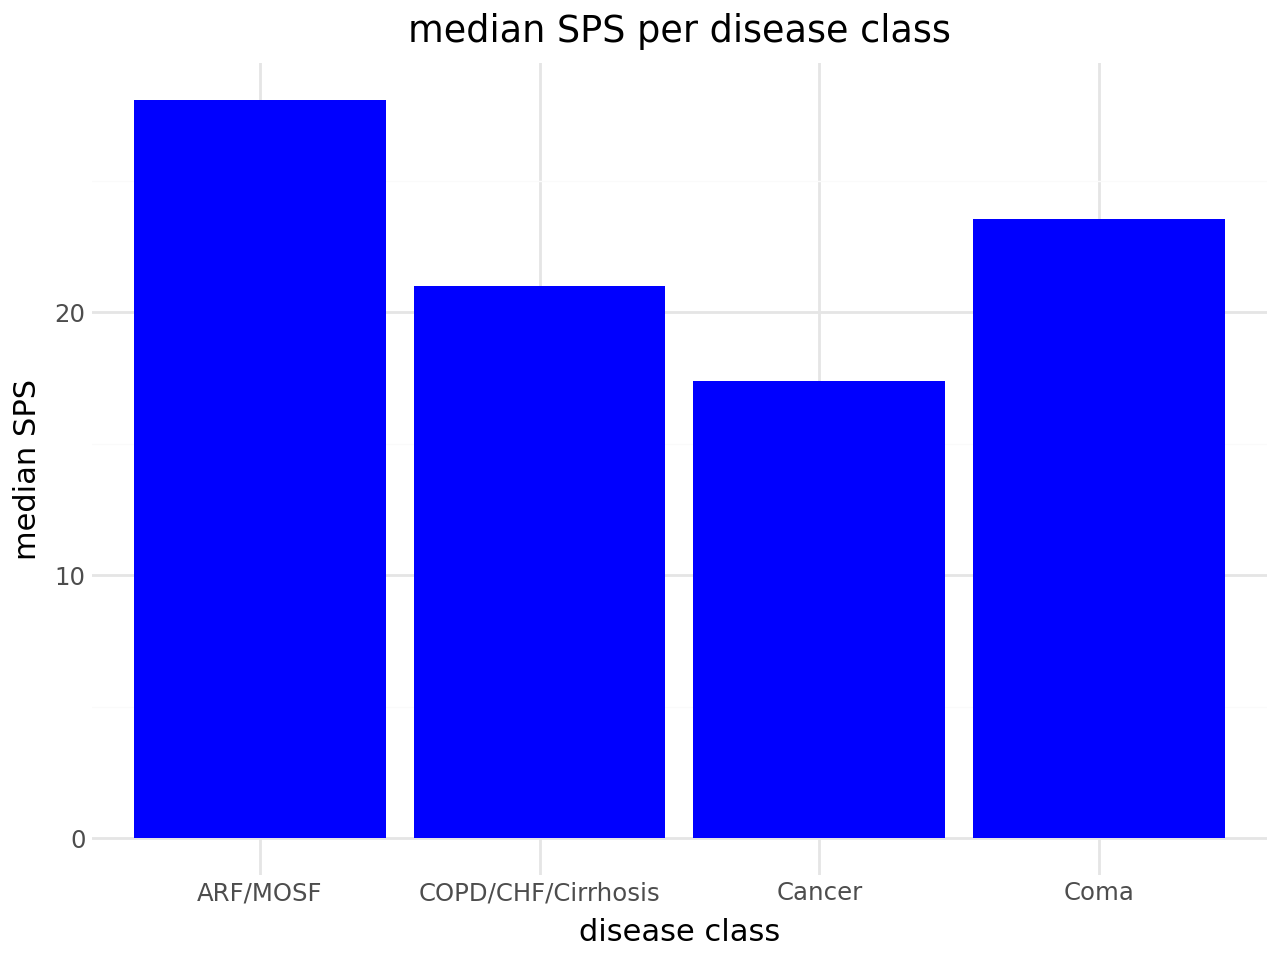

In [61]:
(ggplot(sps_by_class, aes(x='dzclass', y='median_sps'))
 + geom_col(fill='blue')
 + xlab('disease class') + ylab('median SPS')
 + ggtitle('median SPS per disease class')
 + theme_minimal())

This chart shows the SPS per disease class. Higher SPS means the patients in that group were more physiologically severe on average

In [62]:
cost_by_class = df_default.groupby('dzclass')['totcst'].median().reset_index()
cost_by_class.columns = ['dzclass', 'median_cost']
print(cost_by_class)

              dzclass  median_cost
0            ARF/MOSF  31657.57030
1  COPD/CHF/Cirrhosis   6983.37890
2              Cancer   5435.42575
3                Coma  19248.60940


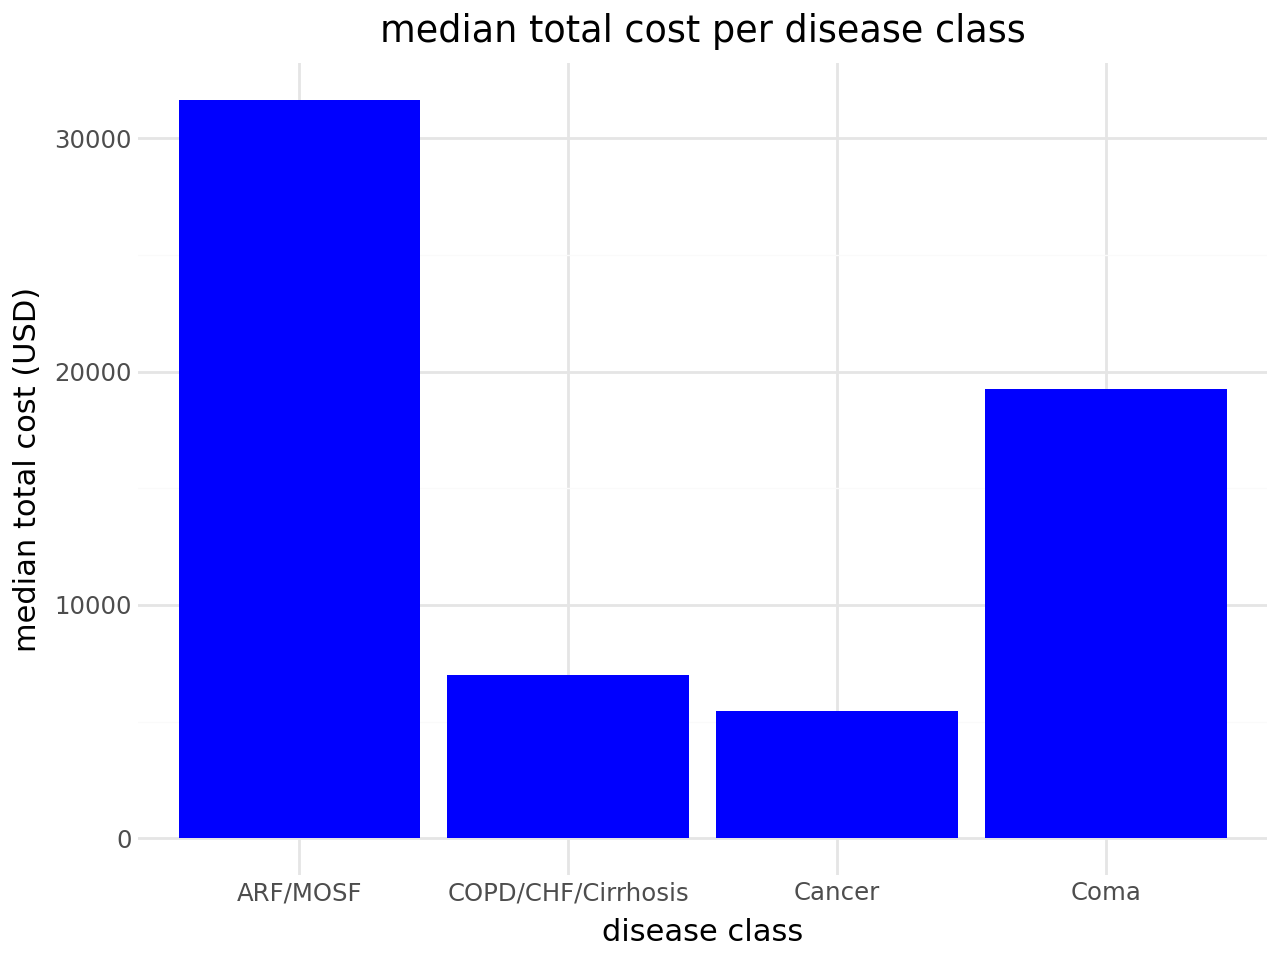

In [63]:
(ggplot(cost_by_class, aes(x='dzclass', y='median_cost'))
 +geom_col(fill='blue')
 +xlab('disease class')+ylab('median total cost (USD)')
 +ggtitle('median total cost per disease class')
 +theme_minimal())

Severity and cost go in the **same order**: ARF/MOSF has the highest median SPS and the highest median cost, then Coma, then COPD/CHF/Cirrhosis, and Cancer is lowest on both. So more severe classes do tend to cost more. But the relationship is not proportional: Coma and COPD/CHF/Cirrhosis have fairly similar SPS (23.5 vs 21), while the median cost of Coma is almost 3 times higher. Severity alone does not explain cost; the type of care (for example ICU treatment) matters too.

*Corrected after the course:* the first version of this comment did not match the charts.

----------------------------------------------------------------------------------------------------------------------------------
Dropping rows where race or edu_group column has missing value for visualization because they have no meaningful interpretation


In [64]:
df_edu = df.dropna(subset=['edu_group']).copy()
df_edu = df_edu[df_edu['race'] != 'unknown' ].copy() 
df_edu.head(3) 


,age,sex,num.co,diabetes,dementia,meanbp,hrt,resp,temp,crea,...,ca,scoma,dzclass,sps,urine,ph,race,edu,death,edu_group
0,62.84998,male,0,0,0,97.0,69.0,22.0,36.00000,1.199951,...,metastatic,0.0,Cancer,33.898438,NaN,7.459961,other,11.0,0,secondary
1,60.33899,female,2,0,0,43.0,112.0,34.0,34.59375,5.500000,...,no,44.0,COPD/CHF/Cirrhosis,52.695312,NaN,7.250000,white,12.0,1,college
2,52.74698,female,2,0,0,70.0,88.0,28.0,37.39844,2.000000,...,no,0.0,COPD/CHF/Cirrhosis,20.500000,NaN,7.459961,white,12.0,1,college


c:\Users\grhnu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\plotnine\stats\stat_density.py:179: PlotnineWarning: To compute the density of a group with only one value set the bandwidth manually. e.g `bw=0.1`
c:\Users\grhnu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\plotnine\stats\stat_density.py:184: PlotnineWarning: Groups with fewer than 2 data points have been removed.


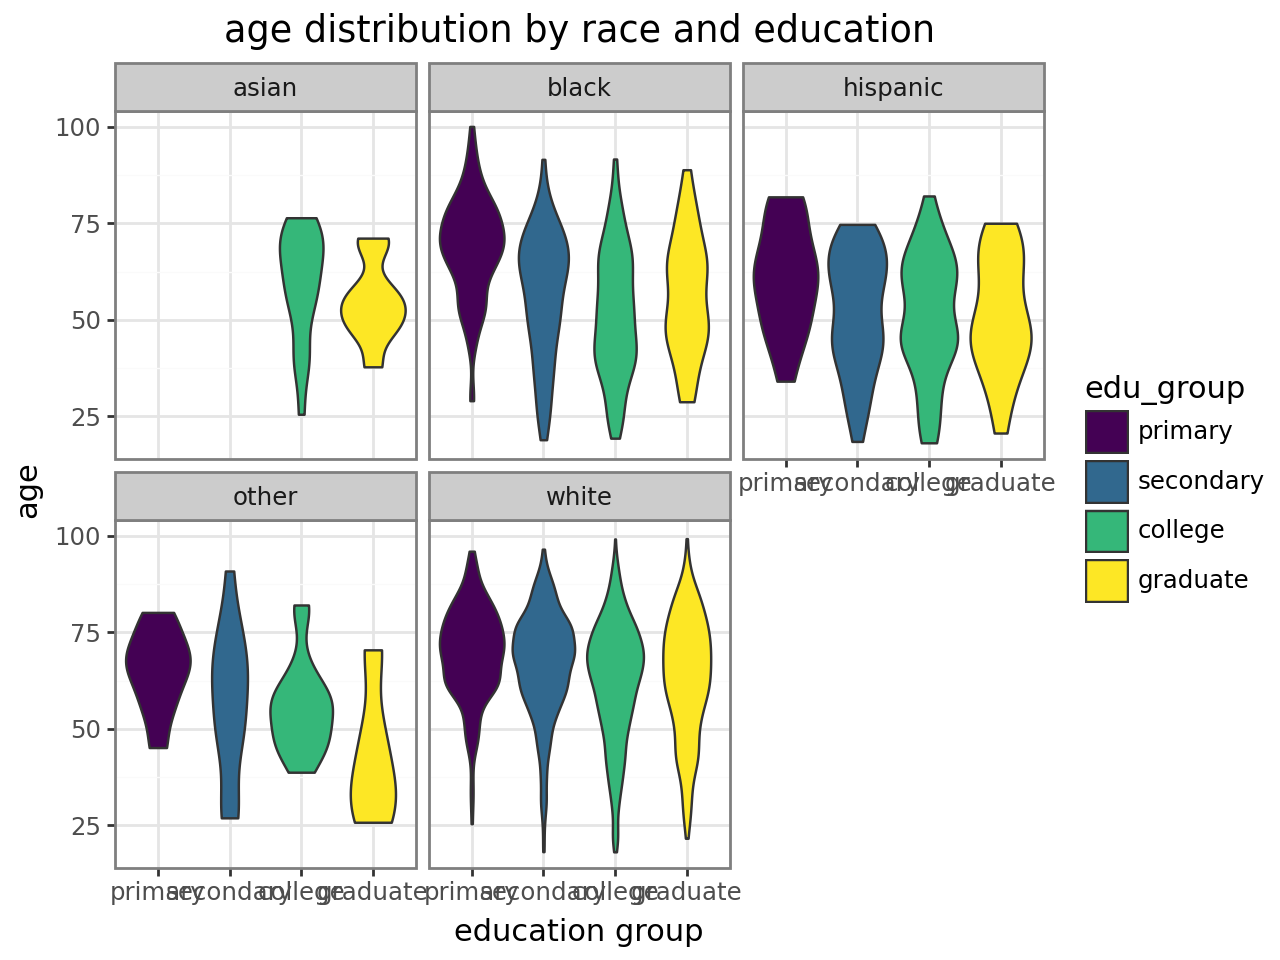

In [65]:
(ggplot(df_edu, aes(x='edu_group', y='age', fill='edu_group'))
 +geom_violin()
 +facet_wrap('~race')
 +xlab('education group') + ylab('age')
 +ggtitle('age distribution by race and education')
 +theme_bw())

Patients with lower education tend to be older across all racial groups. This is consistent with historical trends older generations had less access to higher education. The pattern is visible in all groups but some racial groups have smaller sample sizes which makes their distributions less stable.

In [66]:
import ipywidgets as widgets

selector = widgets.Dropdown(
    options=sorted(df['dzclass'].unique().tolist()),
    description = 'disease class:',
    style={'description_width': 'initial'}
)

out = widgets.Output()

def update(change):
    selected = selector.value
    subset = df[df['dzclass'] == selected].copy() 
    subset['outcome'] = subset['death'].map({0 : 'survived', 1: 'died'})

    p = (ggplot(subset, aes(x = 'outcome', y = 'adlsc', fill = 'outcome'))
         +geom_boxplot()
         +xlab('outcome')+ylab('ADL score')
         +ggtitle(selected)
         +theme_minimal()
         +theme(figure_size=(3,4)))
    
    stats = subset.groupby('outcome')['adlsc'].agg(['count', 'mean','median','std'])

    out.clear_output(wait=True)
    with out:
        display(p)
        display(stats)

selector.observe(update, names = 'value')
update(None)
display(selector, out)

Dropdown(description='disease class:', options=('ARF/MOSF', 'COPD/CHF/Cirrhosis', 'Cancer', 'Coma'), style=Des…

Output()

Static version of the interactive chart above (the dropdown widget does not render on GitHub), showing all disease classes side by side.

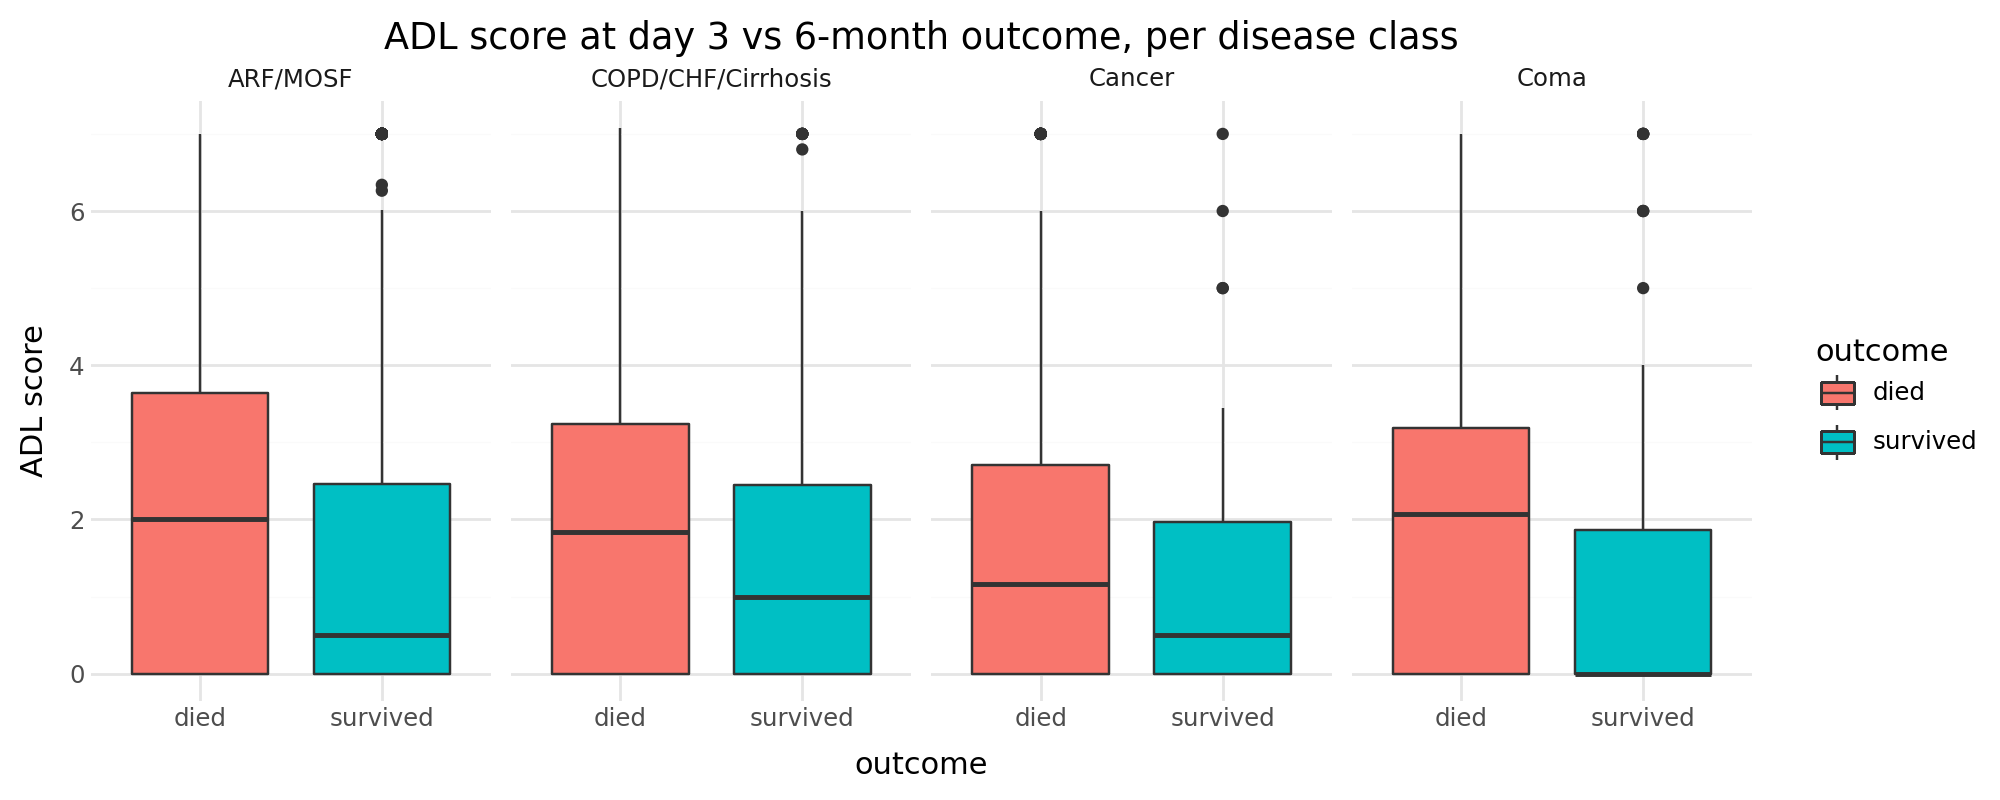

In [67]:
df_plot = df.copy()
df_plot['outcome'] = df_plot['death'].map({0: 'survived', 1: 'died'})

(ggplot(df_plot, aes(x='outcome', y='adlsc', fill='outcome'))
 + geom_boxplot()
 + facet_wrap('~dzclass', nrow=1)
 + xlab('outcome') + ylab('ADL score')
 + ggtitle('ADL score at day 3 vs 6-month outcome, per disease class')
 + theme_minimal()
 + theme(figure_size=(10, 4)))

In most disease classes patients who died have higher ADL scores at day 3 meaning they were more functionally dependent. This suggests that ADL score is a useful predictor of 6-month mortality. In the cancer group the difference is smaller cancer patients can still be functionally independent at day 3 even if their survival chance is poor.

## 4 - Data Analysis

We build a classifier that predicts death(0=survived, 1=died) from the features available at day 3.

In [68]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
# we exclude totcst,totmcst,dzclass_death_rate because of leakage and already dropped
# features that available at day 3
numeric_cols = ['age', 'meanbp', 'hrt', 'resp', 'temp', 'crea', 'sod', 'urine','scoma','ph', 'adlsc','edu','sps','num.co'] 
cat_cols= ['sex', 'race','dzclass', 'ca'] # these will ve one hot encoded because model is not understand categorical values 
binary_cols = ['diabetes','dementia']
x = df[numeric_cols + cat_cols + binary_cols].copy()
y = df['death'].copy()

print('y value counts = (1=died, 0=survived)', y.value_counts())
print(f'death rate = {y.mean()*100:.2f}%')


y value counts = (1=died, 0=survived) death
1    6201
0    2904
Name: count, dtype: int64
death rate = 68.11%


We split the data into train(%81) and test(%19).
 
stratify = y is ensures both sets have the same death rate as the original dataset and random state is for get the same results 


In [69]:
x_train,x_test,y_train,y_test = train_test_split(x,y, random_state=7, train_size=0.81, stratify=y)

print('train death rate = ', round(y_train.mean()*100, 1),'%')
print('test death rate = ', round(y_test.mean()*100, 1),'%') #for confirm 'stratify = y' works

train death rate =  68.1 %
test death rate =  68.1 %


Imputing missing values fit on train only

We fill ph seperately with the training mean and all other numeric columns are filled with training median. 

Both are calculated from training data only, we never use test data statistics to avoid leakage.

'fit_transform' learns the median from training data and applies it. 'transform' applies that same learned median to the test set without learning anything new from it

In [70]:
other_numeric = numeric_cols.copy()
other_numeric.remove('ph')

ph_mean = x_train['ph'].mean()
x_train['ph'] = x_train['ph'].fillna(ph_mean)
x_test['ph'] = x_test['ph'].fillna(ph_mean)

imputer = SimpleImputer(strategy='median')
x_train[other_numeric] = imputer.fit_transform(x_train[other_numeric])
x_test[other_numeric] = imputer.transform(x_test[other_numeric])

print('missing values in x_train after imputation:',x_train[numeric_cols].isna().sum().sum(),
'\nmissing values in x_test after imputation:', x_test[numeric_cols].isna().sum().sum())

missing values in x_train after imputation: 0 
missing values in x_test after imputation: 0


StandardScaler makes all numerical features have mean = 0 , std = 1

In [71]:
scaler = StandardScaler()
x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])
x_test[numeric_cols] = scaler.transform(x_test[numeric_cols])



Model cant understand the categorical values so we convert them into numerical values with one hot encoder

handle_unknown = ignore, means ig test  has a category not seen in training put 0 instead of crashing

sparse_output = false, tells it to return a regular numpy array instead of sparse matrix

In [72]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False) 

#fit on train only, then apply to both
train_encoded = encoder.fit_transform(x_train[cat_cols])
test_encoded = encoder.transform(x_test[cat_cols])


encoded_col_names = encoder.get_feature_names_out(cat_cols)#get the new columns that one hot encoding created

train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_col_names, index=x_train.index)
test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_col_names, index = x_test.index) # converting encoded arrays to dataframes to be able to concat later

x_train = x_train.drop(columns=cat_cols)
x_test = x_test.drop(columns=cat_cols)#dropping original categorical columns

x_train = pd.concat([x_train, train_encoded_df], axis=1)
x_test = pd.concat([x_test, test_encoded_df], axis = 1)# replacing with encoded ones


print('x_train shape after encoding:', x_train.shape)
print('x_test shape after encoding', x_test.shape)

x_train shape after encoding: (7375, 31)
x_test shape after encoding (1730, 31)


Train the model

We choose Decision tree because it works like a series of simple yes/no questions on the data, that makes it easy to understand and explain how it reaches a prediction.

In [73]:
dtc = DecisionTreeClassifier(max_depth=5, random_state=5) # max_depth = 5 is for avoid overfitting
dtc.fit(x_train,y_train) # training the model
print('model trained')

model trained


Cross validation on training set

Cross validation splits the training set into 5 parts, trains on 4 and test on 1 and repeating 5 times. 

This gives a more reliable performance estimate than a single split.

In [74]:
cv_acc = cross_val_score(dtc, x_train, y_train, cv=5, scoring='accuracy')
cv_f1 = cross_val_score(dtc, x_train, y_train, cv=5, scoring='f1_macro')

print('cross validation results:\n')
print(f'accuracy = {cv_acc.mean():.3f} +- {cv_acc.std():.3f}')
print(f'f1 macro = {cv_f1.mean():.3f} +- {cv_f1.std():.3f}')

cross validation results:

accuracy = 0.718 +- 0.009
f1 macro = 0.629 +- 0.021


Evaluate on the test set

In [75]:
y_pred = dtc.predict(x_test)
print('test set results: ')
print(f'accuracy : {accuracy_score(y_test,y_pred):.3f}')
print(f'f1 macro : {f1_score(y_test,y_pred,average='macro'):.3f}\n')

print('classification report: ')
print(classification_report(y_test,y_pred, target_names=['Survived', 'Died']))
print('confusion matrix : ')
print(confusion_matrix(y_test,y_pred))


test set results: 
accuracy : 0.717
f1 macro : 0.589

classification report: 
              precision    recall  f1-score   support

    Survived       0.64      0.25      0.36       552
        Died       0.73      0.94      0.82      1178

    accuracy                           0.72      1730
   macro avg       0.69      0.59      0.59      1730
weighted avg       0.70      0.72      0.67      1730

confusion matrix : 
[[ 138  414]
 [  76 1102]]


The model predicts 6 months mortality from measurements taken at day 3 of the hospital stays.

Since 68% of patients in the dataset died, a model that always predicts 'died' would already get 68% accuracy without learning anything useful. So we look at F1 macro which treats both classes equally.

Missing a patient  who is actually  going to die is more dangerous than a false alarm, so we also check recall score for the died class in the classification report.

In [76]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000, random_state= 12)
lr.fit(x_train, y_train)
y_pred_lr = lr.predict(x_test)

print(f'Decision tree accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'Logistic regression accuracy: {accuracy_score(y_test,y_pred_lr):.3f}')

Decision tree accuracy: 0.717
Logistic regression accuracy: 0.745


We compared Decision tree with Logistic regression. Logistic regression reached a higher test accuracy (0.745 vs 0.717), while the decision tree is easier to interpret. Section 5 repeats this comparison more carefully, using several metrics.

## 5 - Improvements after the course

In this section I rebuild the model in a cleaner and fairer way:

1. **One scikit-learn `Pipeline`** does imputation, scaling and encoding. Inside cross-validation, every fold learns its own medians and scalers, so no information leaks from the validation fold.
2. **A baseline** (always predict the majority class) shows what 'no learning' looks like.
3. **Several models** are compared with the same 5-fold cross-validation.
4. **Better metrics** for an imbalanced target: F1 macro, ROC-AUC and recall of the *survived* class (the original tree found only 25% of survivors).

In [77]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, recall_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Same features and same split as Section 4 (same random_state), but starting from the raw columns
x = df[numeric_cols + cat_cols + binary_cols].copy()
y = df['death'].copy()
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=7, train_size=0.81, stratify=y)

other_numeric = [c for c in numeric_cols if c != 'ph']

# Preprocessing: same imputation strategy as Section 2 (ph -> mean, other numbers -> median)
preprocess = ColumnTransformer([
    ('ph', Pipeline([('impute', SimpleImputer(strategy='mean')), ('scale', StandardScaler())]), ['ph']),
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), other_numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('bin', 'passthrough', binary_cols),
])

# Candidate models. class_weight='balanced' makes the model care more about the smaller class (survived)
models = {
    'Baseline (always died)': DummyClassifier(strategy='most_frequent'),
    'Decision tree': DecisionTreeClassifier(max_depth=5, random_state=5),
    'Decision tree (balanced)': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=5),
    'Logistic regression': LogisticRegression(max_iter=1000),
    'Logistic regression (balanced)': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Gradient boosting (balanced)': HistGradientBoostingClassifier(class_weight='balanced', random_state=7),
}

Cross-validation on the training set only. The test set stays untouched until the very end.

In [78]:
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
scoring = {'accuracy': 'accuracy',
           'f1_macro': 'f1_macro',
           'roc_auc': 'roc_auc',
           'recall_survived': make_scorer(recall_score, pos_label=0)}  # recall of class 0

rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    res = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name,
                 'accuracy': res['test_accuracy'].mean(),
                 'f1_macro': res['test_f1_macro'].mean(),
                 'roc_auc': res['test_roc_auc'].mean(),
                 'recall_survived': res['test_recall_survived'].mean()})

cv_results = pd.DataFrame(rows).set_index('model').round(3)
cv_results

,accuracy,f1_macro,roc_auc,recall_survived
model,,,,
Baseline (always died),0.681,0.405,0.500,0.000
Decision tree,0.719,0.621,0.738,0.333
Decision tree (balanced),0.679,0.661,0.743,0.700
Logistic regression,0.732,0.660,0.772,0.426
Logistic regression (balanced),0.684,0.668,0.772,0.733
Gradient boosting (balanced),0.712,0.687,0.771,0.669


**Reading the table:** the baseline gets about 68% accuracy without learning anything, which is why accuracy alone is misleading here. Balancing the classes trades a bit of accuracy for a much better recall of survivors. Gradient boosting (balanced) has the best F1 macro and ROC-AUC, so it is the final model. The balanced logistic regression is very close and simpler, so it would be a good choice if interpretability matters more.

In [79]:
final_model = Pipeline([('prep', preprocess),
                        ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=7))])
final_model.fit(x_train, y_train)

y_pred_final = final_model.predict(x_test)
y_prob_final = final_model.predict_proba(x_test)[:, 1]

print('TEST SET - gradient boosting (balanced)')
print(f'accuracy        : {accuracy_score(y_test, y_pred_final):.3f}')
print(f'f1 macro        : {f1_score(y_test, y_pred_final, average="macro"):.3f}')
print(f'ROC-AUC         : {roc_auc_score(y_test, y_prob_final):.3f}')
print(f'recall survived : {recall_score(y_test, y_pred_final, pos_label=0):.3f}\n')
print(classification_report(y_test, y_pred_final, target_names=['Survived', 'Died']))

TEST SET - gradient boosting (balanced)
accuracy        : 0.701
f1 macro        : 0.676
ROC-AUC         : 0.769
recall survived : 0.663

              precision    recall  f1-score   support

    Survived       0.52      0.66      0.59       552
        Died       0.82      0.72      0.77      1178

    accuracy                           0.70      1730
   macro avg       0.67      0.69      0.68      1730
weighted avg       0.73      0.70      0.71      1730



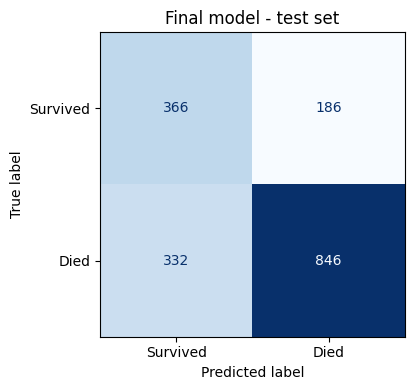

In [80]:
# Confusion matrix of the final model (also saved for the README)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=['Survived', 'Died'],
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Final model - test set')
plt.tight_layout()
plt.savefig('../images/confusion_matrix.png', dpi=150)
plt.show()

Which features matter most? **Permutation importance** shuffles one column at a time and measures how much the test ROC-AUC drops. A bigger drop means the model relies more on that feature.

feature  importance
     ca      0.1116
    sps      0.0611
    age      0.0400
  scoma      0.0270
  urine      0.0122
  adlsc      0.0107
dzclass      0.0084
 num.co      0.0064
   crea      0.0051
    sex      0.0019


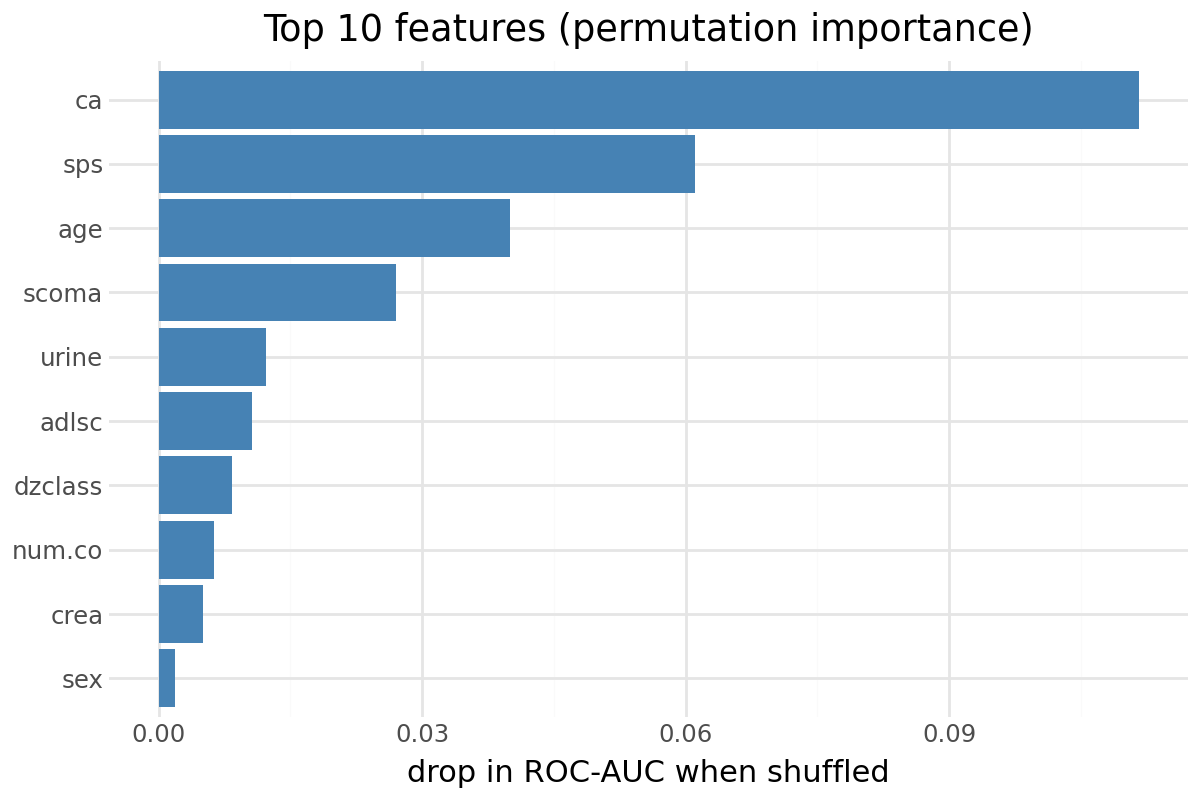

In [81]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(final_model, x_test, y_test, scoring='roc_auc', n_repeats=10, random_state=7)
importance = (pd.DataFrame({'feature': x_test.columns, 'importance': imp.importances_mean})
              .sort_values('importance', ascending=False).head(10))
print(importance.round(4).to_string(index=False))

p = (ggplot(importance, aes(x='reorder(feature, importance)', y='importance'))
     + geom_col(fill='steelblue')
     + coord_flip()
     + xlab('') + ylab('drop in ROC-AUC when shuffled')
     + ggtitle('Top 10 features (permutation importance)')
     + theme_minimal()
     + theme(figure_size=(6, 4)))
p.save('../images/feature_importance.png', dpi=150, verbose=False)
p

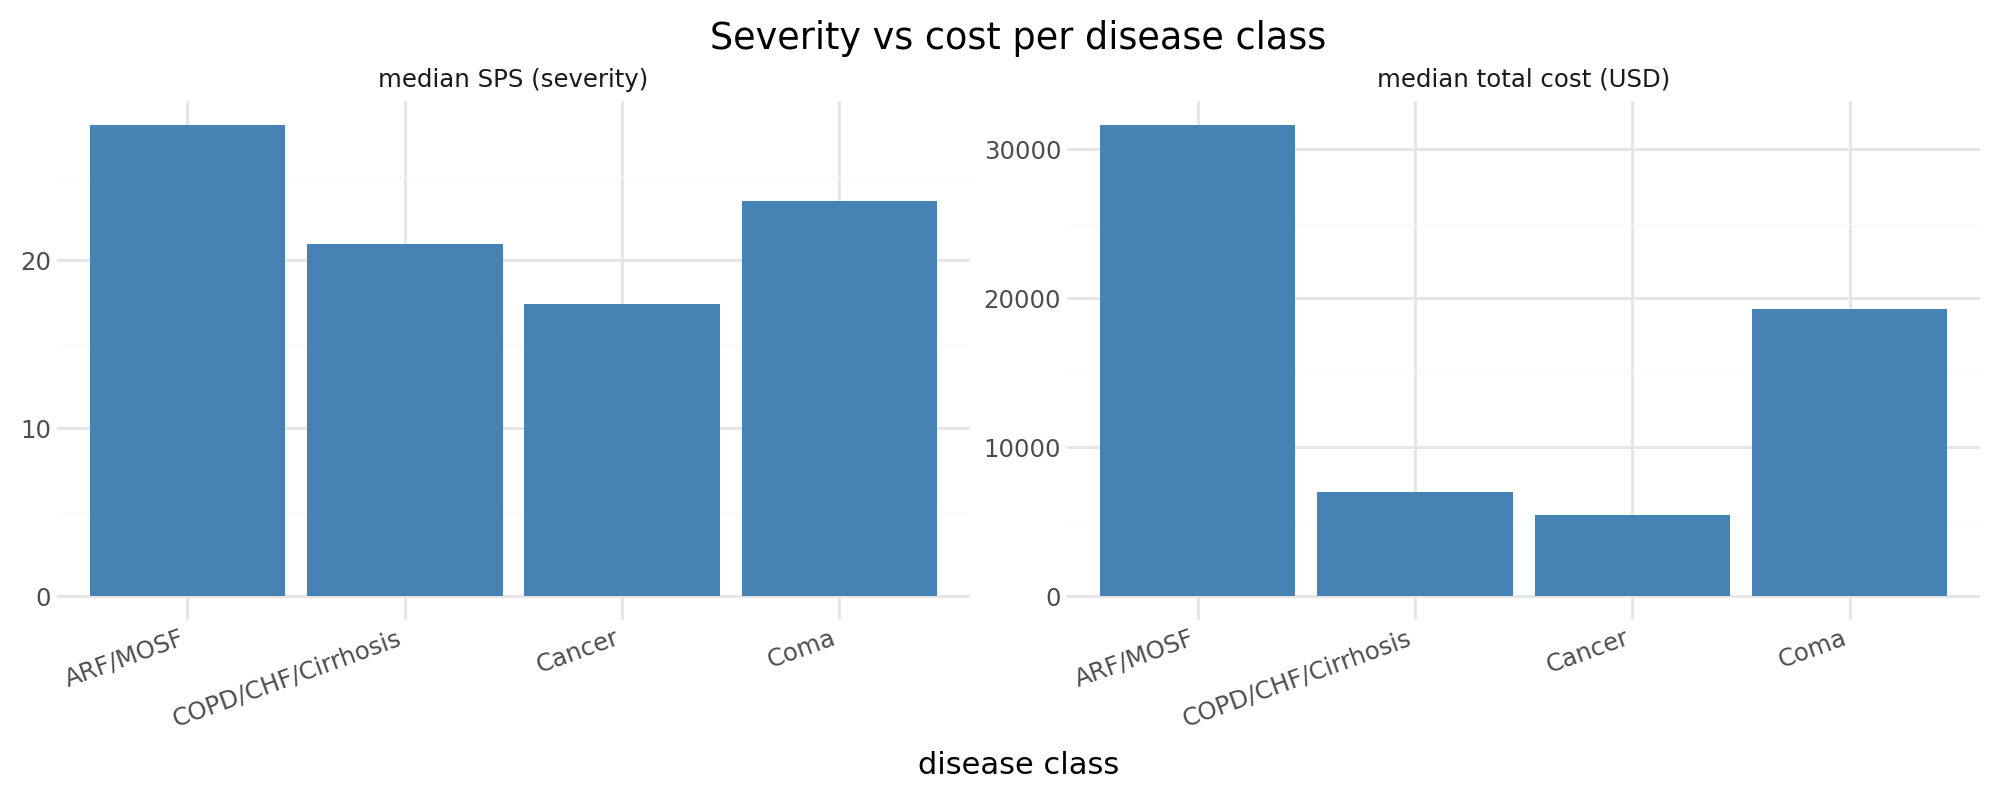

In [82]:
both = sps_by_class.merge(cost_by_class, on='dzclass')
long = pd.concat([
    both.assign(metric='median SPS (severity)', value=both['median_sps'])[['dzclass', 'metric', 'value']],
    both.assign(metric='median total cost (USD)', value=both['median_cost'])[['dzclass', 'metric', 'value']],
])
p2 = (ggplot(long, aes(x='dzclass', y='value'))
      + geom_col(fill='steelblue')
      + facet_wrap('~metric', scales='free_y')
      + xlab('disease class') + ylab('')
      + ggtitle('Severity vs cost per disease class')
      + theme_minimal()
      + theme(figure_size=(10, 4), axis_text_x=element_text(rotation=20, ha='right')))
p2.save('../images/severity_vs_cost.png', dpi=150, verbose=False)
p2

## Summary

**Section 1:** Cleaning, removed duplicates, dropped leakage columns (costs and the target-derived `dzclass_death_rate`), dropped useless columns, fixed -999 in scoma, filled race NaN as 'unknown', fixed data types, created edu_group.

**Section 2:** Quality, checked missing values per column, chose imputation strategy.

**Section 3:** Median cost and SPS bar charts per disease class, age by education and race chart, interactive chart of ADL score vs mortality per disease class.

**Section 4:** Classification: split -> impute -> scale -> encode -> decision tree -> cross validation -> test evaluation.

**Section 5:** one leakage-safe scikit-learn Pipeline, a baseline, six models compared with 5-fold CV on F1 macro / ROC-AUC / survivor recall, final gradient boosting model evaluated on the test set, and permutation feature importance.